# 09 - Routing and payment path (Dashboard 6)

**Question:** how does the generator build the route of a payment: how many banks, which label (`Direct` / `Indirect` / `Covered`), where the gaps go, and why the ends of the path sometimes differ from the BIC columns?

Columns studied: `bic8_path`, `participant_count`, `transaction_type_code`, `continuity_qflag`, with the path features from `03_features` (`path_entries`, `path_gaps`, `path_first_differs`, `path_last_differs`).

Notebook `08_consistency` already proved the fixed links (count = banks in the path, `Direct` = 2 banks, flag = gap). This notebook reconstructs the **random choices**: the distributions and probabilities behind those columns.

- Data: `feat` view (features file) through `src/eda.py`, DuckDB, UTC.
- Charts are saved to `reports/figures/` with the prefix `R`.

Run the cells top to bottom.

## 0. Setup

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda
from src import settings as S

con = eda.connect()
eda.require_columns("feat", ["path_entries", "path_gaps", "path_first_differs", "path_last_differs",
                             "sender_country", "receiver_country", "is_domestic", "party_pair"])
q = eda.q

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

EXPECTED_ROWS = 10_000_000
BLUE, ORANGE, RED, GREEN, GREY = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8C8C8C"

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


### Working table `route`
One row per payment with only the columns this notebook needs, plus the first and last bank of the path. Built once in memory; takes a few seconds.

In [2]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE route AS
    SELECT participant_count                       AS banks,
           participant_count - 1                   AS links,          -- hand-offs between consecutive banks
           transaction_type_code                   AS route_type,
           path_gaps                               AS gaps,
           path_first_differs, path_last_differs,
           ordering_bic8, beneficiary_bic8,
           split_part(bic8_path, ';', 1)           AS first_bank,
           string_split(bic8_path, ';')[-1]        AS last_bank,
           string_split(bic8_path, ';')[2]         AS second_entry,
           substr(split_part(bic8_path, ';', 1), 5, 2)        AS first_country,   -- country of the first bank in the path
           substr(string_split(bic8_path, ';')[-1], 5, 2)     AS last_country,    -- country of the last bank in the path
           sender_country, receiver_country, is_domestic, party_pair, currency_code,
           usd_amount_magnitude, utc_is_weekend, anomaly_type
    FROM feat
""")
N = int(q("SELECT count(*) AS n FROM route").loc[0, "n"])
assert N == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS:,} rows, found {N:,}"
print(f"{N:,} rows in route")

10,000,000 rows in route


## 1. Hypotheses

H-R1 to H-R5 were written **before testing**, from the profiling report and the case study. H-R6 to H-R8 were added when the first results did not fit (see the note under the table).

| ID | Hypothesis | Test |
|---|---|---|
| H-R1 | The number of banks follows a fixed decay: each extra bank is about 0.37 times as likely as one fewer, i.e. extra banks = an exponential random number with mean 1, rounded down | Observed counts against the predicted counts; estimate the ratio from the data |
| H-R2 | Short routes are more likely for domestic payments, big banks or particular customers | Share of 2-bank routes across segments, against the overall share |
| H-R3 | With 3 or more banks, `Indirect` vs `Covered` depends on payment attributes (route length, amount, currency, domestic) | Covered share by each attribute |
| H-R4 | The first-bank and last-bank mismatches (path end is not the BIC column) are two independent 5% events | 2 x 2 table against the independence prediction; rate by route length and type |
| H-R5 | Gaps (`...`) are placed at random, or depend on the route | Gaps per payment by number of banks |
| H-R6 | *(added)* `Covered` is a fixed property of the pair of banks at the two ends of the route | Covered share per bank pair: is every pair 0% or 100%? |
| H-R7 | *(added)* In a mismatched row the two banks (BIC column and path end) are unrelated: one of them is a random draw in proportion to bank volume | Same-country share against chance; counts against each bank's normal volume |
| H-R8 | *(added)* Each hand-off between two banks receives gaps independently with the same probability | Gap counts against the negative-binomial prediction |
| H-R9 | *(added)* Of the two banks in a mismatched row, the **path end** is the one the route was built for; the BIC column (and the account built from it) is the one that deviates | Which pair keeps the normal share of same-country payments: the BIC columns or the path ends? |

**How the hypotheses changed.** H-R3 gave confusing results: the Covered share moved with currency, country and amount but not with route length. Looking at single banks showed shares near 5% for most and near 50% for a few, which suggested a property of bank pairs (H-R6). H-R5 showed 5% of 2-bank routes with a gap and a regular pattern of 2, 3, 4 gaps, which suggested one probability per hand-off (H-R8). H-R4 held, which raised the question of how the two disagreeing banks relate (H-R7). Finally, the mismatch rate turned out to be lower for domestic payments, which should not happen if the BIC columns were the untouched original; that led to H-R9, and to a correction of the wording first used in notebook 08.

## 2. How many banks? (H-R1)

If extra banks (beyond the minimum of 2) are an exponential random number with mean 1, rounded down, then P(k extra) = (1 - r) r^k with r = 1/e = 0.3679. This is a geometric distribution; its ratio r can be estimated from the data as mean / (1 + mean).

In [3]:
dist = q("SELECT banks, count(*) AS observed FROM route GROUP BY 1 ORDER BY 1")
mean_extra = float(((dist.banks - 2) * dist.observed).sum() / N)
r_hat = mean_extra / (1 + mean_extra)                      # maximum-likelihood estimate of the ratio
r_se = (1 - r_hat) * math.sqrt(r_hat / N)                  # its standard error
print(f"Mean extra banks: {mean_extra:.5f}")
print(f"Estimated ratio r: {r_hat:.5f}  (standard error {r_se:.5f}, 95% interval {r_hat - 1.96 * r_se:.5f} to {r_hat + 1.96 * r_se:.5f})")
candidates = pd.DataFrame({"candidate": ["1/e (exponential, mean 1)", "0.37", "0.35", "1/3", "0.40"],
                           "r": [math.exp(-1), 0.37, 0.35, 1 / 3, 0.40]})
candidates["standard_errors_from_estimate"] = ((candidates.r - r_hat) / r_se).round(1)
candidates

Mean extra banks: 0.58157
Estimated ratio r: 0.36772  (standard error 0.00012, 95% interval 0.36748 to 0.36796)


,candidate,r,standard_errors_from_estimate
0,"1/e (exponential, mean 1)",0.3679,1.3000
1,0.37,0.3700,18.8000
2,0.35,0.3500,-146.1000
3,1/3,0.3333,-283.6000
4,0.40,0.4000,266.3000


In [4]:
R = math.exp(-1)
dist["predicted"] = N * (1 - R) * R ** (dist.banks - 2)
p = dist.predicted / N
dist["z"] = (dist.observed - dist.predicted) / np.sqrt(dist.predicted * (1 - p))   # distance in standard deviations
dist["ratio_to_previous"] = dist.observed / dist.observed.shift(1)
main = dist[dist.predicted >= 5]
tail = dist[dist.predicted < 5]
print(f"Route lengths with at least 5 predicted payments: {len(main)} (banks {main.banks.min()} to {main.banks.max()}), "
      f"largest |z| = {main.z.abs().max():.2f}")
print(f"Longer routes: {int(tail.observed.sum())} payments observed, {tail.predicted.sum():.2f} predicted")
dist.assign(predicted=dist.predicted.round(1), z=dist.z.round(2), ratio_to_previous=dist.ratio_to_previous.round(4))

Route lengths with at least 5 predicted payments: 15 (banks 2 to 16), largest |z| = 1.83
Longer routes: 5 payments observed, 2.24 predicted


,banks,observed,predicted,z,ratio_to_previous
0,2,6323280,"6,321,205.6000",1.3600,NaN
1,3,2324319,"2,325,441.6000",-0.8400,0.3676
2,4,855386,"855,482.1000",-0.1100,0.3680
3,5,314014,"314,714.3000",-1.2700,0.3671
4,6,115701,"115,776.9000",-0.2200,0.3685
5,7,42622,"42,591.9000",0.1500,0.3684
6,8,15481,"15,668.7000",-1.5000,0.3632
7,9,5758,"5,764.2000",-0.0800,0.3719
8,10,2205,"2,120.5000",1.8300,0.3829
9,11,769,780.1000,-0.4000,0.3488


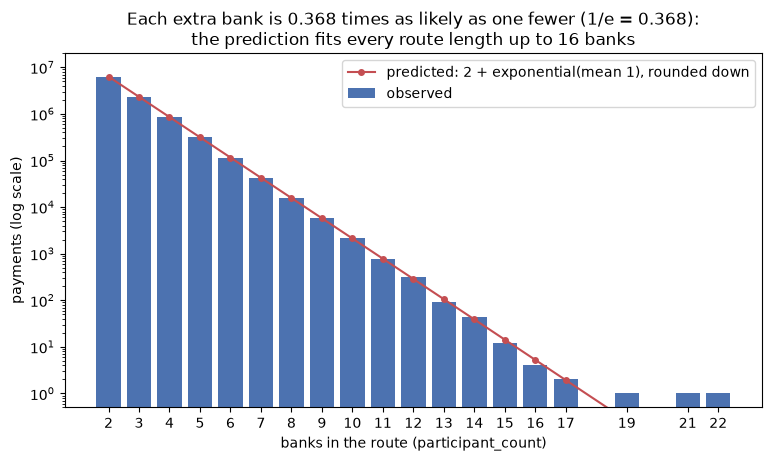

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(dist.banks, dist.observed, color=BLUE, label="observed")
ax.plot(dist.banks, dist.predicted, color=RED, marker="o", ms=4, lw=1.5, label="predicted: 2 + exponential(mean 1), rounded down")
ax.set_yscale("log")
ax.set_ylim(0.5, N * 2)
ax.set_xticks(dist.banks)
ax.set_xlabel("banks in the route (participant_count)")
ax.set_ylabel("payments (log scale)")
ax.legend()
ax.set_title(f"Each extra bank is {r_hat:.3f} times as likely as one fewer (1/e = {R:.3f}):\n"
             f"the prediction fits every route length up to {int(main.banks.max())} banks")
eda.save(fig, "R1_banks_per_payment")
plt.show()

**Result: H-R1 held.** The estimated ratio is within about one standard error of 1/e, and the nearby round values are many standard errors away (table above). The only misfit is the far tail, counted above.

## 3. Does anything change the route length? (H-R2)

Baseline: the share of 2-bank routes over all payments. If a segment sends shorter or longer routes, its share moves away from the baseline. With millions of rows even tiny differences are statistically visible, so the table also gives the difference in percentage points.

In [6]:
base_direct = float(q("SELECT avg((banks = 2)::INT) AS p FROM route").loc[0, "p"])

def by(dimension, label, where="TRUE", order="n DESC", limit=50):
    d = q(f"""
        SELECT '{label}' AS dimension, CAST({dimension} AS VARCHAR) AS segment, count(*) AS n,
               100 * avg((banks = 2)::INT) AS pct_two_banks, avg(banks - 2) AS mean_extra_banks
        FROM route WHERE {where} GROUP BY 2 ORDER BY {order} LIMIT {limit}
    """)
    return d

con.execute("""
    CREATE OR REPLACE TEMP TABLE bank_size AS
    SELECT ordering_bic8 AS bic,
           CASE WHEN count(*) >= 50000 THEN '1. 50,000+ payments' WHEN count(*) >= 5000 THEN '2. 5,000-49,999'
                WHEN count(*) >= 500 THEN '3. 500-4,999' ELSE '4. under 500' END AS size_tier
    FROM route GROUP BY 1
""")
seg = pd.concat([
    by("is_domestic", "domestic payment"),
    by("party_pair", "party pair", order="segment"),
    by("utc_is_weekend", "weekend (UTC)"),
    by("usd_amount_magnitude", "amount, power of 10", where="usd_amount_magnitude BETWEEN 0 AND 6", order="CAST(segment AS INT)"),
    by("sender_country", "sender country (top 5)", limit=5),
    by("receiver_country", "receiver country (top 5)", limit=5),
    by("currency_code", "currency (top 5)", limit=5),
    by("coalesce(anomaly_type, '(normal)')", "anomaly type"),
    q("""SELECT 'sender bank size' AS dimension, size_tier AS segment, count(*) AS n,
                 100 * avg((banks = 2)::INT) AS pct_two_banks, avg(banks - 2) AS mean_extra_banks
          FROM route JOIN bank_size ON route.ordering_bic8 = bank_size.bic GROUP BY 2 ORDER BY 2"""),
], ignore_index=True)
seg["difference_pp"] = seg.pct_two_banks - 100 * base_direct
seg["standard_error_pp"] = 100 * np.sqrt(base_direct * (1 - base_direct) / seg.n)
print(f"Baseline: {100 * base_direct:.3f}% of all payments use 2 banks")
seg.round({"pct_two_banks": 3, "mean_extra_banks": 4, "difference_pp": 3, "standard_error_pp": 3})

Baseline: 63.233% of all payments use 2 banks


,dimension,segment,n,pct_two_banks,mean_extra_banks,difference_pp,standard_error_pp
0,domestic payment,false,9288884,63.2310,0.5816,-0.0010,0.0160
1,domestic payment,true,711116,63.2500,0.5815,0.0170,0.0570
2,party pair,B2B,2270945,63.2170,0.5819,-0.0150,0.0320
3,party pair,B2C,5603692,63.2320,0.5815,-0.0010,0.0200
4,party pair,C2B,610605,63.1900,0.5822,-0.0430,0.0620
5,party pair,C2C,1514758,63.2760,0.5810,0.0430,0.0390
6,weekend (UTC),false,8881524,63.2330,0.5816,-0.0000,0.0160
7,weekend (UTC),true,1118476,63.2350,0.5811,0.0020,0.0460
8,"amount, power of 10",0,122712,63.0780,0.5823,-0.1550,0.1380
9,"amount, power of 10",1,715250,63.2670,0.5817,0.0340,0.0570


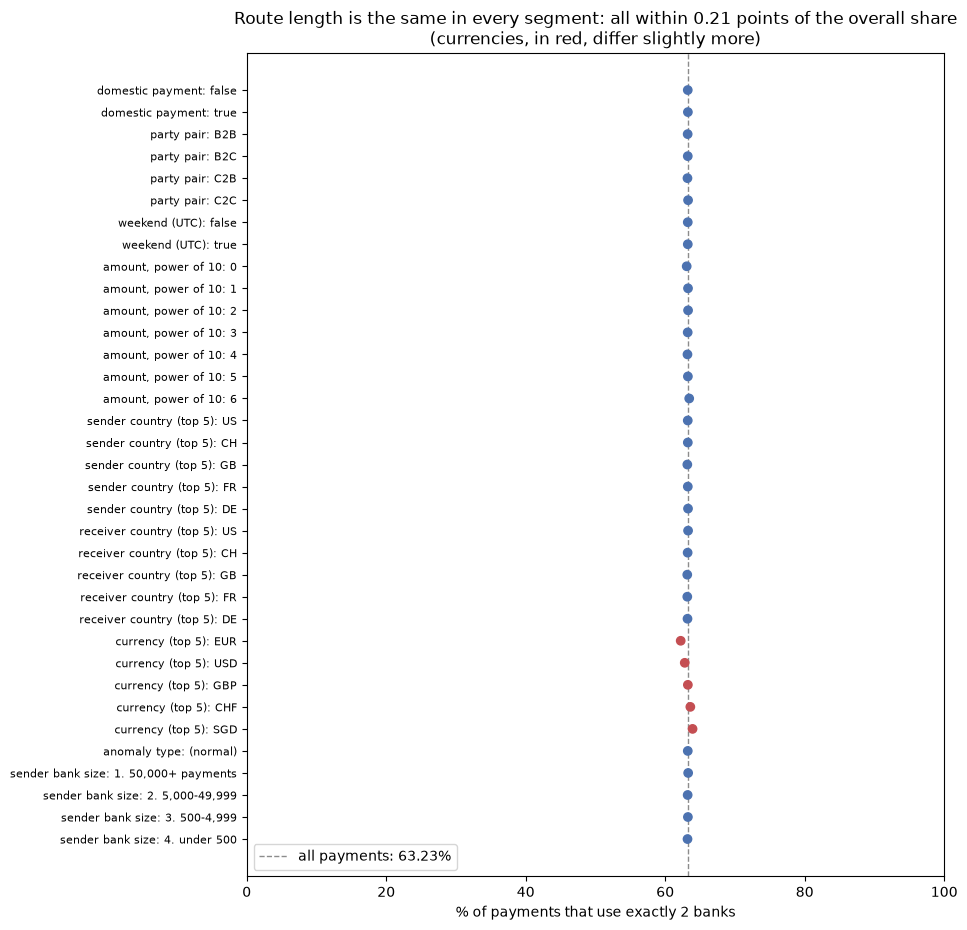

In [7]:
big = seg[seg.n >= 100_000].reset_index(drop=True)          # segments large enough for a stable percentage
colors = [RED if dim.startswith("currency") else BLUE for dim in big.dimension]
fig, ax = plt.subplots(figsize=(9, 0.26 * len(big) + 1.6))
y = np.arange(len(big))[::-1]
ax.scatter(big.pct_two_banks, y, color=colors, zorder=3)
ax.axvline(100 * base_direct, color=GREY, ls="--", lw=1, label=f"all payments: {100 * base_direct:.2f}%")
ax.set_yticks(y)
ax.set_yticklabels([f"{d}: {s}" for d, s in zip(big.dimension, big.segment)], fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("% of payments that use exactly 2 banks")
ax.legend(loc="lower left")
spread = big.loc[~big.dimension.str.startswith("currency"), "difference_pp"].abs().max()
ax.set_title(f"Route length is the same in every segment: all within {spread:.2f} points of the overall share\n"
             "(currencies, in red, differ slightly more)")
eda.save(fig, "R2_route_length_by_segment")
plt.show()

**Result: H-R2 was rejected.** Domestic or cross-border, business or consumer, weekday or weekend, small or large amount, country, bank size: none of them moves the share of 2-bank routes by more than a fraction of a point (chart title). The route length is drawn independently of who pays whom.

The one visible exception is the currency: the largest currencies sit a little below the baseline (size in the table). Section 3.1 shows that this is a side effect of how the currency is chosen, not a rule about route length.

### 3.1 Why the currency moves with route length

Dashboard 3 found that a payment's currency is the home currency of a bank on its route, mostly the first bank. If that is how the currency is chosen, a longer route has more banks that could supply the currency, so it is less often in the first bank's home currency. The currency then follows from the route, not the other way round.

Two checks, on normal payments only (labelled anomalies excluded):

1. The share of payments in the first bank's home currency, by route length. It should fall as banks are added.
2. Among payments in the first bank's home currency only, the share of 2-bank routes per currency. If the currency itself has no effect on the route, the gap between currencies seen above should close.

A country's home currency is computed from the data, exactly as in Dashboard 3: the currency its senders use most.

In [8]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE home AS
    SELECT sender_country AS country, arg_max(currency_code, n) AS home_currency
    FROM (SELECT sender_country, currency_code, count(*) AS n FROM route WHERE anomaly_type IS NULL GROUP BY 1, 2)
    GROUP BY 1
""")
con.execute("""
    CREATE OR REPLACE TEMP TABLE route_home AS
    SELECT r.banks, r.currency_code, (r.currency_code = h.home_currency) AS first_bank_home
    FROM route r JOIN home h ON h.country = r.first_country
    WHERE r.anomaly_type IS NULL
""")
by_len = q("""
    SELECT banks, count(*) AS n, 100 * avg(first_bank_home::INT) AS pct_first_bank_home
    FROM route_home WHERE banks <= 7 GROUP BY 1 ORDER BY 1
""")
top_cur = list(q("SELECT currency_code FROM route GROUP BY 1 ORDER BY count(*) DESC LIMIT 5").currency_code)
cur_list = ", ".join(f"'{c}'" for c in top_cur)
by_cur = q(f"""
    SELECT currency_code,
           100 * avg((banks = 2)::INT)                                  AS pct_two_banks_all,
           100 * avg((banks = 2)::INT) FILTER (WHERE first_bank_home)   AS pct_two_banks_first_bank_home,
           count(*) FILTER (WHERE first_bank_home)                      AS n_first_bank_home
    FROM route_home WHERE currency_code IN ({cur_list}) GROUP BY 1 ORDER BY pct_two_banks_all
""")
print(f"In the first bank's home currency: {by_len.pct_first_bank_home.iloc[0]:.2f}% of 2-bank routes, "
      f"{by_len.pct_first_bank_home.iloc[-1]:.2f}% of {int(by_len.banks.iloc[-1])}-bank routes")
print(f"Spread of the 2-bank share across the top 5 currencies: "
      f"{by_cur.pct_two_banks_all.max() - by_cur.pct_two_banks_all.min():.2f} points over all normal payments, "
      f"{by_cur.pct_two_banks_first_bank_home.max() - by_cur.pct_two_banks_first_bank_home.min():.2f} points "
      f"within payments in the first bank's home currency")
display(by_len)
by_cur

In the first bank's home currency: 94.73% of 2-bank routes, 86.78% of 7-bank routes
Spread of the 2-bank share across the top 5 currencies: 1.70 points over all normal payments, 0.61 points within payments in the first bank's home currency


,banks,n,pct_first_bank_home
0,2,6318885,94.7336
1,3,2322649,92.1325
2,4,854759,90.2112
3,5,313790,88.7428
4,6,115648,87.6323
5,7,42600,86.7840


,currency_code,pct_two_banks_all,pct_two_banks_first_bank_home,n_first_bank_home
0,EUR,62.2184,63.6497,2828414
1,USD,62.7974,64.0119,1533596
2,GBP,63.2486,64.1781,833197
3,CHF,63.6018,64.2197,780968
4,SGD,63.9183,64.2618,361420


**Result.** Both checks fit. The share of payments in the first bank's home currency falls steadily as banks are added, from 94.73% of 2-bank routes to 86.78% of 7-bank routes (first table). Once only payments in the first bank's home currency are kept, the 2-bank shares of the five largest currencies move close together: the spread shrinks from 1.70 to 0.61 points (EUR 63.65%, SGD 64.26%; second table). The currency effect in section 3 is therefore explained: the currency is taken from a bank on the route, mostly the first (Dashboard 3), so it depends on the route and not the reverse. R-R2 holds without an exception.

## 4. Indirect or Covered? (H-R3, H-R6)

By rule R-S3 (notebook 08), a route with 3 or more banks is `Indirect` or `Covered`. What decides which?

### 4.1 Payment attributes (H-R3)

In [9]:
def covered_by(dimension, label, order="n DESC", limit=8, where="TRUE"):
    return q(f"""
        SELECT '{label}' AS dimension, CAST({dimension} AS VARCHAR) AS segment, count(*) AS n,
               100 * avg((route_type = 'Covered')::INT) AS pct_covered
        FROM route WHERE banks >= 3 AND {where} GROUP BY 2 ORDER BY {order} LIMIT {limit}
    """)

base_cov = float(q("SELECT avg((route_type = 'Covered')::INT) AS p FROM route WHERE banks >= 3").loc[0, "p"])
n_multi = int(q("SELECT count(*) AS n FROM route WHERE banks >= 3").loc[0, "n"])
print(f"Baseline: {100 * base_cov:.2f}% of the {n_multi:,} payments with 3+ banks are Covered")
cov = pd.concat([
    covered_by("banks", "number of banks", order="CAST(segment AS INT)", where="banks <= 8"),
    covered_by("gaps", "gaps in path", order="CAST(segment AS INT)", where="gaps <= 3"),
    covered_by("party_pair", "party pair", order="segment"),
    covered_by("is_domestic", "domestic payment"),
    covered_by("currency_code", "currency (top 8)"),
    covered_by("sender_country", "sender country (top 8)"),
    covered_by("receiver_country", "receiver country (top 8)"),
], ignore_index=True)
cov.round({"pct_covered": 2})

Baseline: 11.31% of the 3,676,720 payments with 3+ banks are Covered


,dimension,segment,n,pct_covered
0,number of banks,3,2324319,11.3200
1,number of banks,4,855386,11.2900
2,number of banks,5,314014,11.3300
3,number of banks,6,115701,11.3100
4,number of banks,7,42622,11.3200
5,number of banks,8,15481,11.4300
6,gaps in path,0,3224782,11.3100
7,gaps in path,1,408620,11.3500
8,gaps in path,2,39572,11.3100
9,gaps in path,3,3449,11.3700


The Covered share does not move with route length, gaps or party pair, but it moves a lot with the sender's country and the currency, and less with the receiver's country. That pattern points at the **sending bank**, not at the payment.

### 4.2 Bank pairs (H-R6)

For every pair of banks with at least 100 multi-bank payments, the share that is Covered. The pair is identified in two ways: by the two BIC columns, and by the first and last bank written in the path (these differ in about 5% of rows each, section 5).

In [10]:
pairs_cols = q("""
    SELECT ordering_bic8 AS bank_a, beneficiary_bic8 AS bank_b, count(*) AS n, 100 * avg((route_type = 'Covered')::INT) AS pct_covered
    FROM route WHERE banks >= 3 GROUP BY 1, 2 HAVING count(*) >= 100
""")
pairs_path = q("""
    SELECT first_bank AS bank_a, last_bank AS bank_b, count(*) AS n, 100 * avg((route_type = 'Covered')::INT) AS pct_covered
    FROM route WHERE banks >= 3 GROUP BY 1, 2 HAVING count(*) >= 100
""")

def summary(d, name):
    return pd.Series({"pairs with 100+ payments": len(d),
                      "pairs exactly 0% Covered": int((d.pct_covered == 0).sum()),
                      "pairs exactly 100% Covered": int((d.pct_covered == 100).sum()),
                      "pairs in between": int(((d.pct_covered > 0) & (d.pct_covered < 100)).sum())}, name=name)

pd.concat([summary(pairs_cols, "pair = the two BIC columns"), summary(pairs_path, "pair = first and last bank in the path")], axis=1)

,pair = the two BIC columns,pair = first and last bank in the path
pairs with 100+ payments,3496,3825
pairs exactly 0% Covered,2246,3040
pairs exactly 100% Covered,214,785
pairs in between,1036,0


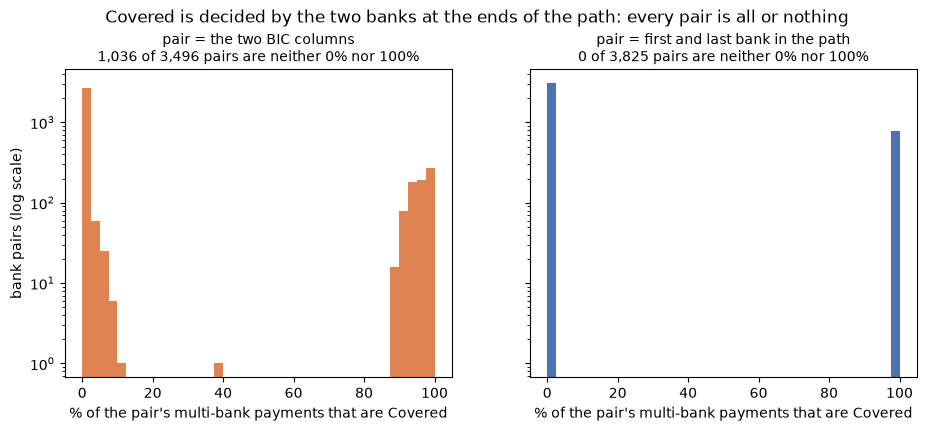

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
bins = np.arange(0, 102.5, 2.5)
for ax, d, title, color in [(axes[0], pairs_cols, "pair = the two BIC columns", ORANGE),
                            (axes[1], pairs_path, "pair = first and last bank in the path", BLUE)]:
    ax.hist(d.pct_covered, bins=bins, color=color)
    ax.set_yscale("log")
    ax.set_xlabel("% of the pair's multi-bank payments that are Covered")
    between = int(((d.pct_covered > 0) & (d.pct_covered < 100)).sum())
    ax.set_title(f"{title}\n{between:,} of {len(d):,} pairs are neither 0% nor 100%", fontsize=10)
axes[0].set_ylabel("bank pairs (log scale)")
fig.suptitle("Covered is decided by the two banks at the ends of the path: every pair is all or nothing", y=1.03)
eda.save(fig, "R3_covered_by_endpoint_pair")
plt.show()

The chart uses pairs with 100+ payments so that a percentage is meaningful. The rule itself can be checked on **every** pair, however small: does any pair of path ends have both a Covered and an Indirect payment?

In [12]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE end_pairs AS
    SELECT first_bank, last_bank, count(*) AS n, sum((route_type = 'Covered')::INT) AS n_covered
    FROM route WHERE banks >= 3 GROUP BY 1, 2
""")
allp = q("""
    SELECT count(*)                                         AS pairs,
           sum((n_covered = 0)::INT)                        AS never_covered,
           sum((n_covered = n)::INT)                        AS always_covered,
           sum((n_covered > 0 AND n_covered < n)::INT)      AS mixed,
           sum(n)                                           AS payments,
           sum(n_covered)                                   AS covered_payments,
           sum((n >= 2)::INT)                               AS pairs_with_2_or_more_payments,
           sum((n >= 2 AND n_covered = n)::INT)             AS always_covered_with_2_or_more
    FROM end_pairs
""").iloc[0]
mixed_cols = int(q("""
    SELECT count(*) AS mixed FROM (
        SELECT ordering_bic8, beneficiary_bic8 FROM route WHERE banks >= 3 GROUP BY 1, 2
        HAVING sum((route_type = 'Covered')::INT) > 0 AND sum((route_type = 'Covered')::INT) < count(*))
""").loc[0, "mixed"])
print(f"Pairs of path ends with multi-bank payments : {int(allp.pairs):,}")
print(f"  never Covered                              : {int(allp.never_covered):,}")
print(f"  always Covered ('cover pairs')             : {int(allp.always_covered):,} ({100 * allp.always_covered / allp.pairs:.2f}% of pairs, "
      f"{100 * allp.covered_payments / allp.payments:.2f}% of payments)")
print(f"  mixed (both labels)                        : {int(allp.mixed):,}")
print(f"For comparison, mixed pairs when the pair is taken from the BIC columns: {mixed_cols:,}")
print(f"Pairs with 2+ payments (where a mix was possible): {int(allp.pairs_with_2_or_more_payments):,}, "
      f"of which always Covered: {int(allp.always_covered_with_2_or_more):,}")

Pairs of path ends with multi-bank payments : 618,954
  never Covered                              : 597,519
  always Covered ('cover pairs')             : 21,435 (3.46% of pairs, 11.31% of payments)
  mixed (both labels)                        : 0
For comparison, mixed pairs when the pair is taken from the BIC columns: 20,251
Pairs with 2+ payments (where a mix was possible): 322,631, of which always Covered: 15,335


### 4.3 What makes a pair a cover pair?

Three checks: is it symmetric (if A to B is a cover pair, is B to A?), does it depend on the two banks being in the same country, and does it depend on the size of the banks?

In [13]:
symmetry = q("""
    SELECT CASE WHEN a.n_covered = a.n THEN 'A to B: cover pair' ELSE 'A to B: not' END AS direction_1,
           CASE WHEN b.n_covered = b.n THEN 'B to A: cover pair' ELSE 'B to A: not' END AS direction_2,
           count(*) AS bank_pairs_seen_in_both_directions
    FROM end_pairs a JOIN end_pairs b ON a.first_bank = b.last_bank AND a.last_bank = b.first_bank
    WHERE a.first_bank < a.last_bank GROUP BY 1, 2 ORDER BY 1, 2
""")
display(symmetry)
q("""
    SELECT substr(first_bank, 5, 2) = substr(last_bank, 5, 2) AS same_country, count(*) AS pairs,
           100 * avg((n_covered = n)::INT) AS pct_cover_pairs, sum(n) AS payments,
           100.0 * sum(n_covered) / sum(n) AS pct_covered_payments
    FROM end_pairs GROUP BY 1 ORDER BY 1
""").round(2)

,direction_1,direction_2,bank_pairs_seen_in_both_directions
0,A to B: cover pair,B to A: cover pair,175
1,A to B: cover pair,B to A: not,2324
2,A to B: not,B to A: cover pair,2818
3,A to B: not,B to A: not,65353


,same_country,pairs,pct_cover_pairs,payments,pct_covered_payments
0,False,582190,3.0900,"3,409,292.0000",10.5800
1,True,36764,9.4100,"267,428.0000",20.6900


In [14]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE bank_volume AS
    SELECT bic, sum(n) AS volume FROM (
        SELECT ordering_bic8 AS bic, count(*) AS n FROM route GROUP BY 1
        UNION ALL SELECT beneficiary_bic8, count(*) FROM route GROUP BY 1) GROUP BY 1
""")
tier = """CASE WHEN {v} >= 100000 THEN 'A. 100,000+' WHEN {v} >= 20000 THEN 'B. 20,000-99,999'
              WHEN {v} >= 2000 THEN 'C. 2,000-19,999' ELSE 'D. under 2,000' END"""
size = q(f"""
    SELECT {tier.format(v='v1.volume')} AS first_bank_volume, {tier.format(v='v2.volume')} AS last_bank_volume,
           count(*) AS pairs, 100 * avg((p.n_covered = p.n)::INT) AS pct_cover_pairs
    FROM end_pairs p JOIN bank_volume v1 ON p.first_bank = v1.bic JOIN bank_volume v2 ON p.last_bank = v2.bic
    GROUP BY 1, 2
""")
print("% of pairs that are cover pairs, by the payment volume of the first bank (rows) and last bank (columns):")
display(size.pivot(index="first_bank_volume", columns="last_bank_volume", values="pct_cover_pairs").round(1))
print("Number of pairs behind each cell:")
size.pivot(index="first_bank_volume", columns="last_bank_volume", values="pairs")

% of pairs that are cover pairs, by the payment volume of the first bank (rows) and last bank (columns):


last_bank_volume,"A. 100,000+","B. 20,000-99,999","C. 2,000-19,999","D. under 2,000"
first_bank_volume,,,,
"A. 100,000+",63.3000,36.9000,17.8000,19.0000
"B. 20,000-99,999",4.4000,2.2000,1.7000,2.3000
"C. 2,000-19,999",2.2000,1.4000,1.5000,3.1000
"D. under 2,000",0.9000,1.3000,2.9000,8.2000


Number of pairs behind each cell:


last_bank_volume,"A. 100,000+","B. 20,000-99,999","C. 2,000-19,999","D. under 2,000"
first_bank_volume,,,,
"A. 100,000+",210,3219,17438,23223
"B. 20,000-99,999",2642,33964,120452,80963
"C. 2,000-19,999",4988,50831,109857,55954
"D. under 2,000",8352,39297,46945,20615


**Result: H-R3 was rejected, H-R6 held.** The payment's own attributes do not decide the label. Each ordered pair (first bank in path, last bank in path) carries a fixed answer, with no mixed pair in the whole dataset; the differences by country and currency in 4.1 are a by-product of which banks sit in those segments. The label follows the banks **written in the path**, not the BIC columns: with the BIC columns, pairs look "5% noisy" because the path end is replaced in about 5% of rows (section 5).

Which pairs are cover pairs is only partly explained: the property is one-directional, more common inside one country, and much more common when the first bank is one of the largest (tables above).

## 5. Path ends that differ from the BIC columns (H-R4, H-R7, H-R9)

`path_first_differs`: the first bank in the path is not `ordering_bic8`. `path_last_differs`: the last bank is not `beneficiary_bic8`.

### 5.1 Two independent events (H-R4)

In [15]:
two = q("SELECT path_first_differs AS first_differs, path_last_differs AS last_differs, count(*) AS observed FROM route GROUP BY 1, 2 ORDER BY 1, 2")
p_first = float(two.loc[two.first_differs, "observed"].sum() / N)
p_last = float(two.loc[two.last_differs, "observed"].sum() / N)
two["expected_if_independent"] = [N * (p_first if f else 1 - p_first) * (p_last if l else 1 - p_last)
                                  for f, l in zip(two.first_differs, two.last_differs)]
two["z"] = (two.observed - two.expected_if_independent) / np.sqrt(two.expected_if_independent)
print(f"First bank differs: {100 * p_first:.3f}% of payments | last bank differs: {100 * p_last:.3f}%")
two.round({"expected_if_independent": 1, "z": 2})

First bank differs: 4.984% of payments | last bank differs: 4.993%


,first_differs,last_differs,observed,expected_if_independent,z
0,False,False,9027029,"9,027,219.3000",-0.0600
1,False,True,474572,"474,381.7000",0.2800
2,True,False,473706,"473,515.7000",0.2800
3,True,True,24693,"24,883.3000",-1.2100


In [16]:
pd.concat([
    q("""SELECT 'banks in route' AS dimension, CAST(banks AS VARCHAR) AS segment, count(*) AS n,
                 100 * avg(path_first_differs::INT) AS pct_first_differs, 100 * avg(path_last_differs::INT) AS pct_last_differs
          FROM route WHERE banks <= 6 GROUP BY 2 ORDER BY CAST(segment AS INT)"""),
    q("""SELECT 'route type' AS dimension, route_type AS segment, count(*) AS n,
                 100 * avg(path_first_differs::INT) AS pct_first_differs, 100 * avg(path_last_differs::INT) AS pct_last_differs
          FROM route GROUP BY 2 ORDER BY 2"""),
    q("""SELECT 'party pair' AS dimension, party_pair AS segment, count(*) AS n,
                 100 * avg(path_first_differs::INT) AS pct_first_differs, 100 * avg(path_last_differs::INT) AS pct_last_differs
          FROM route GROUP BY 2 ORDER BY 2"""),
    q("""SELECT 'label' AS dimension, CASE WHEN anomaly_type IS NULL THEN 'normal' ELSE 'anomaly' END AS segment, count(*) AS n,
                 100 * avg(path_first_differs::INT) AS pct_first_differs, 100 * avg(path_last_differs::INT) AS pct_last_differs
          FROM route GROUP BY 2 ORDER BY 2 DESC"""),
    q("""SELECT 'domestic (by BIC columns)' AS dimension, CAST(is_domestic AS VARCHAR) AS segment, count(*) AS n,
                 100 * avg(path_first_differs::INT) AS pct_first_differs, 100 * avg(path_last_differs::INT) AS pct_last_differs
          FROM route GROUP BY 2 ORDER BY 2"""),
], ignore_index=True).round(2)

,dimension,segment,n,pct_first_differs,pct_last_differs
0,banks in route,2,6323280,4.9800,5.0000
1,banks in route,3,2324319,4.9900,4.9700
2,banks in route,4,855386,4.9500,5.0000
3,banks in route,5,314014,5.0100,5.0800
4,banks in route,6,115701,5.0700,4.9800
5,route type,Covered,415962,4.9300,5.0100
6,route type,Direct,6323280,4.9800,5.0000
7,route type,Indirect,3260758,4.9900,4.9800
8,party pair,B2B,2270945,4.9900,5.0100
9,party pair,B2C,5603692,4.9800,4.9900


The two mismatches are independent of each other (z values near 0) and of the route length, route type and party pair. Two segments stand out:

- **Anomaly rows** have fewer mismatches. Notebook 02 already showed that scam rows never have a last-bank mismatch.
- **Domestic payments** (sender and receiver BIC columns in the same country) have clearly fewer mismatches. That is a clue about which of the two banks is the odd one out, tested next.

### 5.2 Which of the two banks deviates? (H-R9)

Normal payments have a preference for staying inside one country: the share of same-country pairs is well above what two unrelated banks would give. In a mismatched row there are two candidate pairs: the pair written in the **BIC columns** and the pair at the **ends of the path**. The pair that still shows the normal same-country share is the one the payment was built around; the pair that has dropped to the chance level contains an unrelated bank.

In [17]:
direction = q("""
    SELECT CASE WHEN NOT path_first_differs AND NOT path_last_differs THEN '1. both ends match'
                WHEN path_first_differs AND NOT path_last_differs     THEN '2. only the first bank differs'
                WHEN NOT path_first_differs AND path_last_differs     THEN '3. only the last bank differs'
                ELSE '4. both differ' END                                    AS rows_where,
           count(*)                                                          AS n,
           100 * avg((sender_country = receiver_country)::INT)               AS pct_same_country_bic_columns,
           100 * avg((first_country = last_country)::INT)                    AS pct_same_country_path_ends
    FROM route GROUP BY 1 ORDER BY 1
""")
# Chance level: the share of same-country pairs if the sender-side bank were unrelated to the receiver-side bank
chance_pair = float(q("""
    WITH s AS (SELECT sender_country AS cc, count(*) * 1.0 / (SELECT count(*) FROM route) AS p FROM route GROUP BY 1),
         r AS (SELECT receiver_country AS cc, count(*) * 1.0 / (SELECT count(*) FROM route) AS p FROM route GROUP BY 1)
    SELECT 100 * sum(s.p * r.p) AS chance FROM s JOIN r USING (cc)
""").loc[0, "chance"])
print(f"Same-country share if the two banks were unrelated (chance level): {chance_pair:.2f}%")
direction.round(3)

Same-country share if the two banks were unrelated (chance level): 5.62%


,rows_where,n,pct_same_country_bic_columns,pct_same_country_path_ends
0,1. both ends match,9027029,7.2770,7.2770
1,2. only the first bank differs,473706,5.6410,7.2600
2,3. only the last bank differs,474572,5.5070,7.3310
3,4. both differ,24693,5.4020,7.2210


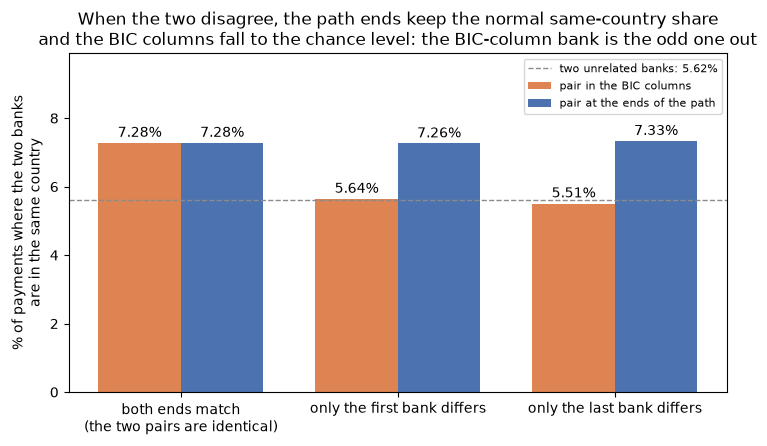

In [18]:
d = direction.iloc[:3]
x = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
b1 = ax.bar(x - 0.19, d.pct_same_country_bic_columns, width=0.38, color=ORANGE, label="pair in the BIC columns")
b2 = ax.bar(x + 0.19, d.pct_same_country_path_ends, width=0.38, color=BLUE, label="pair at the ends of the path")
ax.bar_label(b1, fmt="%.2f%%", padding=2)
ax.bar_label(b2, fmt="%.2f%%", padding=2)
ax.axhline(chance_pair, color=GREY, ls="--", lw=1, label=f"two unrelated banks: {chance_pair:.2f}%")
ax.set_xticks(x)
ax.set_xticklabels(["both ends match\n(the two pairs are identical)", "only the first bank differs", "only the last bank differs"])
ax.set_ylim(0, d[["pct_same_country_bic_columns", "pct_same_country_path_ends"]].to_numpy().max() * 1.35)
ax.set_ylabel("% of payments where the two banks\nare in the same country")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("When the two disagree, the path ends keep the normal same-country share\n"
             "and the BIC columns fall to the chance level: the BIC-column bank is the odd one out")
eda.save(fig, "R4_which_bank_deviates")
plt.show()

This agrees with section 4: the `Covered` label follows the path ends, not the BIC columns. Two independent pieces of evidence point the same way.

### 5.3 How is the deviating bank chosen? (H-R7)

If the BIC-column bank in a mismatched row is a fresh random draw, then (a) it should share the country of the path-end bank no more often than chance, and (b) every bank should turn up as the deviating bank in proportion to its normal volume.

In [19]:
def deviating(side_col, flag, own_country, path_country):
    d = q(f"""
        SELECT {side_col} AS bic,
               count(*) FILTER (WHERE NOT {flag}) AS normal_payments,
               count(*) FILTER (WHERE {flag})     AS times_as_deviating_bank
        FROM route GROUP BY 1
    """)
    same = float(q(f"SELECT 100 * avg(({own_country} = {path_country})::INT) AS p FROM route WHERE {flag}").loc[0, "p"])
    chance = float(q(f"""
        WITH a AS (SELECT {own_country} AS cc, count(*) * 1.0 / (SELECT count(*) FROM route) AS p FROM route GROUP BY 1),
             b AS (SELECT {path_country} AS cc, count(*) * 1.0 / (SELECT count(*) FROM route) AS p FROM route GROUP BY 1)
        SELECT 100 * sum(a.p * b.p) AS chance FROM a JOIN b USING (cc)
    """).loc[0, "chance"])
    slope = float((d.times_as_deviating_bank * d.normal_payments).sum() / (d.normal_payments ** 2).sum())   # line through the origin
    return {"mismatched rows": int(d.times_as_deviating_bank.sum()),
            "banks seen as the deviating bank": int((d.times_as_deviating_bank > 0).sum()),
            "correlation with the bank's normal volume": round(float(d.times_as_deviating_bank.corr(d.normal_payments)), 4),
            "deviating appearances per 100 normal payments": round(100 * slope, 3),
            "same country as the path-end bank (%)": round(same, 2),
            "same country by chance (%)": round(chance, 2)}

pd.DataFrame({
    "sender side (ordering_bic8 vs first bank in path)": deviating("ordering_bic8", "path_first_differs", "sender_country", "first_country"),
    "receiver side (beneficiary_bic8 vs last bank in path)": deviating("beneficiary_bic8", "path_last_differs", "receiver_country", "last_country"),
})

,sender side (ordering_bic8 vs first bank in path),receiver side (beneficiary_bic8 vs last bank in path)
mismatched rows,"498,399.0000","499,265.0000"
banks seen as the deviating bank,"6,330.0000","5,681.0000"
correlation with the bank's normal volume,0.9994,0.9813
deviating appearances per 100 normal payments,5.2350,5.7030
same country as the path-end bank (%),4.8300,5.8700
same country by chance (%),5.0400,6.3400


Is the mismatch a property of certain accounts, or does it strike any payment? For every sender account with at least 200 payments, the share of its payments where the path starts at a different bank:

In [20]:
q("""
    WITH a AS (SELECT ordering_account, count(*) AS n, 100 * avg(path_first_differs::INT) AS pct FROM feat GROUP BY 1 HAVING count(*) >= 200)
    SELECT count(*) AS sender_accounts_with_200_plus_payments, sum(n) AS payments,
           round(min(pct), 2) AS lowest_pct, round(quantile_cont(pct, 0.05), 2) AS pct_5th, round(median(pct), 2) AS median_pct,
           round(quantile_cont(pct, 0.95), 2) AS pct_95th, round(max(pct), 2) AS highest_pct,
           sum((pct = 0)::INT) AS accounts_never_mismatched, sum((pct > 20)::INT) AS accounts_above_20_pct
    FROM a
""")

,sender_accounts_with_200_plus_payments,payments,lowest_pct,pct_5th,median_pct,pct_95th,highest_pct,accounts_never_mismatched,accounts_above_20_pct
0,8532,"5,883,912.0000",0.9400,3.2000,4.9500,6.8800,9.9500,0.0000,0.0000


**Result: H-R4, H-R9 and H-R7 held.** At each end of the route, about 5% of payments name a party whose bank is not the bank at that end of the path. The two ends behave independently, and the mismatch strikes individual payments, not particular accounts (table above). The path ends are the pair the route was built for (they keep the same-country preference and they carry the `Covered` label); the party's bank in the BIC column is unrelated to the route in those rows: it matches the path-end bank's country only at the chance rate. Each bank appears in that role in line with its volume: almost exactly so on the sender side, approximately on the receiver side (correlations in the table).

Because the account is always built from the BIC-column bank (notebook 08, R-S8), the account in such a row belongs to the unrelated bank too.

## 6. Gaps in the path (H-R5, H-R8)

A route with *k* banks has *k - 1* hand-offs (links). Suppose that at every link the generator inserts a gap with probability g, and then again with probability g, until it stops. Then the gaps of one link follow a geometric distribution, and the total over *k - 1* links follows a negative binomial: P(m gaps) = C(m + k - 2, m) g^m (1 - g)^(k - 1).

In [21]:
gaps = q("SELECT banks, links, gaps, count(*) AS observed FROM route GROUP BY 1, 2, 3")
total_gaps = int((gaps.gaps * gaps.observed).sum())
total_links = int((gaps.links * gaps.observed).sum())
per_link = total_gaps / total_links
g_hat = per_link / (1 + per_link)                              # maximum-likelihood estimate of the gap probability
g_se = (1 - g_hat) * math.sqrt(g_hat / total_links)
print(f"{total_gaps:,} gaps over {total_links:,} links = {per_link:.5f} gaps per link")
print(f"Estimated gap probability g: {g_hat:.5f} (standard error {g_se:.5f}); 0.05 is {(0.05 - g_hat) / g_se:+.1f} standard errors away")

G = 0.05
row_totals = gaps.groupby("banks")["observed"].transform("sum")
gaps["predicted"] = [n * math.comb(int(m + L - 1), int(m)) * G ** m * (1 - G) ** L for n, m, L in zip(row_totals, gaps.gaps, gaps.links)]
gaps["z"] = (gaps.observed - gaps.predicted) / np.sqrt(gaps.predicted)
cells = gaps[gaps.predicted >= 5]
print(f"Cells (banks x gaps) with at least 5 predicted payments: {len(cells)}, largest |z| = {cells.z.abs().max():.2f}, "
      f"cells beyond 3 standard deviations: {int((cells.z.abs() > 3).sum())}")
show = gaps[(gaps.banks <= 5) & (gaps.gaps <= 4)].sort_values(["banks", "gaps"])
show.assign(predicted=show.predicted.round(1), z=show.z.round(2))

831,251 gaps over 15,815,715 links = 0.05256 gaps per link
Estimated gap probability g: 0.04993 (standard error 0.00005); 0.05 is +1.2 standard errors away
Cells (banks x gaps) with at least 5 predicted payments: 59, largest |z| = 2.06, cells beyond 3 standard deviations: 0


,banks,links,gaps,observed,predicted,z
63,2,1,0,6008014,"6,007,116.0000",0.3700
45,2,1,1,299417,"300,355.8000",-1.7100
22,2,1,2,15076,"15,017.8000",0.4800
6,2,1,3,739,750.9000,-0.4300
72,2,1,4,30,37.5000,-1.2300
0,3,2,0,2097906,"2,097,697.9000",0.1400
50,3,2,1,209705,"209,769.8000",-0.1400
36,3,2,2,15638,"15,732.7000",-0.7600
59,3,2,3,998,"1,048.8000",-1.5700
34,3,2,4,69,65.6000,0.4300


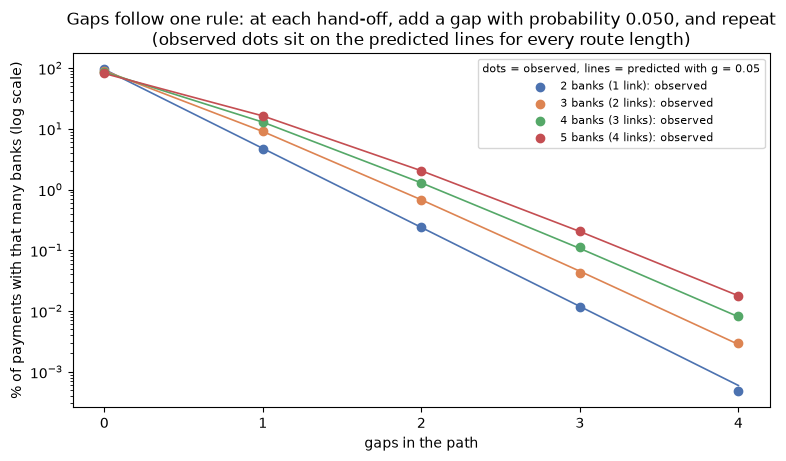

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.6))
palette = {2: BLUE, 3: ORANGE, 4: GREEN, 5: RED}
for banks, color in palette.items():
    d = gaps[(gaps.banks == banks) & (gaps.predicted >= 5)].sort_values("gaps")   # cells with too few payments are left out
    if d.empty:
        continue
    total = gaps.loc[gaps.banks == banks, "observed"].sum()
    ax.scatter(d.gaps, 100 * d.observed / total, color=color, zorder=3, label=f"{banks} banks ({banks - 1} link{'s' if banks > 2 else ''}): observed")
    ax.plot(d.gaps, 100 * d.predicted / total, color=color, lw=1.2)
ax.set_yscale("log")
ax.set_xticks(range(0, int(gaps.loc[gaps.predicted >= 5, "gaps"].max()) + 1))
ax.set_xlabel("gaps in the path")
ax.set_ylabel("% of payments with that many banks (log scale)")
ax.legend(fontsize=8, title="dots = observed, lines = predicted with g = 0.05", title_fontsize=8)
ax.set_title(f"Gaps follow one rule: at each hand-off, add a gap with probability {g_hat:.3f}, and repeat\n"
             "(observed dots sit on the predicted lines for every route length)")
eda.save(fig, "R5_gaps_per_link")
plt.show()

**Control checks.** Is the gap probability the same in every kind of route, and is a single gap equally likely at each link?

In [23]:
ctrl = pd.concat([
    q("SELECT 'route type' AS dimension, route_type AS segment, sum(links) AS links, sum(gaps) * 1.0 / sum(links) AS gaps_per_link FROM route GROUP BY 2 ORDER BY 2"),
    q("SELECT 'domestic payment' AS dimension, CAST(is_domestic AS VARCHAR) AS segment, sum(links) AS links, sum(gaps) * 1.0 / sum(links) AS gaps_per_link FROM route GROUP BY 2 ORDER BY 2"),
    q("SELECT 'party pair' AS dimension, party_pair AS segment, sum(links) AS links, sum(gaps) * 1.0 / sum(links) AS gaps_per_link FROM route GROUP BY 2 ORDER BY 2"),
    q("SELECT 'label' AS dimension, CASE WHEN anomaly_type IS NULL THEN 'normal' ELSE 'anomaly' END AS segment, sum(links) AS links, sum(gaps) * 1.0 / sum(links) AS gaps_per_link FROM route GROUP BY 2 ORDER BY 2 DESC"),
    q("SELECT 'endpoint replaced' AS dimension, CAST(path_first_differs OR path_last_differs AS VARCHAR) AS segment, sum(links) AS links, sum(gaps) * 1.0 / sum(links) AS gaps_per_link FROM route GROUP BY 2 ORDER BY 2"),
], ignore_index=True)
ctrl["implied_g"] = ctrl.gaps_per_link / (1 + ctrl.gaps_per_link)
display(ctrl.round({"gaps_per_link": 5, "implied_g": 5}))
q("""
    SELECT CASE WHEN second_entry = '...' THEN 'gap at link 1 (after the first bank)' ELSE 'gap at link 2 (before the last bank)' END AS position,
           count(*) AS payments_with_3_banks_and_1_gap
    FROM route WHERE banks = 3 AND gaps = 1 GROUP BY 1 ORDER BY 1
""")

,dimension,segment,links,gaps_per_link,implied_g
0,route type,Covered,"1,074,045.0000",0.0527,0.0501
1,route type,Direct,"6,323,280.0000",0.0525,0.0499
2,route type,Indirect,"8,418,390.0000",0.0526,0.0500
3,domestic payment,false,"14,691,088.0000",0.0526,0.0499
4,domestic payment,true,"1,124,627.0000",0.0526,0.0499
5,party pair,B2B,"3,592,516.0000",0.0526,0.0500
6,party pair,B2C,"8,862,238.0000",0.0525,0.0499
7,party pair,C2B,"966,106.0000",0.0524,0.0498
8,party pair,C2C,"2,394,855.0000",0.0527,0.0500
9,label,normal,"15,804,688.0000",0.0526,0.0499


,position,payments_with_3_banks_and_1_gap
0,gap at link 1 (after the first bank),104890
1,gap at link 2 (before the last bank),104815


**Result: H-R5 is refined by H-R8, which held.** Gaps do not depend on the route type, the parties or the label. They depend on the route length only because a longer route has more links, each with the same small chance of a gap.

## 7. Results: reconstructed rules (all checked on 10,000,000 rows)

Every number below is printed by a cell above.

### The route recipe, in the order the evidence suggests

1. **Number of banks.** Draw an exponential random number with mean 1, round it down, add 2.
2. **Ends of the route.** Choose the first and last bank (how banks are chosen is the subject of the bank network dashboard).
3. **Label.** 2 banks: `Direct`. 3 or more: `Covered` if the ordered pair (first bank, last bank) is on a fixed list of cover pairs, otherwise `Indirect`.
4. **Gaps.** For each hand-off between two consecutive banks: with probability 0.05 insert `...`, and repeat until the draw fails.
5. **Parties.** The sender is a customer of the first bank, except in about 5% of payments, where the sender's bank is an unrelated bank. The same holds, independently, for the receiver and the last bank.
6. **Derived columns.** `participant_count`, `continuity_qflag` and the `Direct` label then follow from the path (notebook 08).

### Rules

| ID | Rule: condition → effect | Size and scope | Evidence | Confidence |
|---|---|---|---|---|
| R-R1 | Extra banks beyond 2 follow P(k) = (1 - r) r^k with r = 1/e. Each extra bank is 0.368 times as likely as one fewer. | Estimated r = 0.36772 (standard error 0.00012); 1/e = 0.36788 is 1.3 standard errors away, 0.37 is 18.8 away. 63.23% of payments have 2 banks. All 15 route lengths with 5+ predicted payments (2 to 16 banks) are within 1.83 standard deviations. | Section 2, chart R1 | High. Does not apply to the far tail: 5 payments with 17 to 22 banks against 2.24 predicted. |
| R-R2 | The route length does not depend on who pays whom. | Share of 2-bank routes is within 0.21 percentage points of 63.23% in every segment with 100,000+ payments: domestic or not, party pair, weekend, amount size, top countries, sender bank size. | Section 3, chart R2 | High. The currencies differ slightly (EUR 62.22%, USD 62.80%, SGD 63.92%), but this is a side effect of the currency rule, not an exception: the currency is taken from a bank on the route, mostly the first, so longer routes are less often in the first bank's currency (94.73% at 2 banks, 86.78% at 7; section 3.1, Dashboard 3). |
| R-R3 | For routes with 3+ banks, the label is fixed by the ordered pair (first bank in path, last bank in path): 21,435 cover pairs are always `Covered`, all other pairs always `Indirect`. | 618,954 pairs, 3,676,720 payments, **0 pairs with both labels** (322,631 pairs had 2+ payments, so a mix was possible). Cover pairs are 3.46% of pairs and carry 11.31% of multi-bank payments. | Section 4, chart R3 | Certain for the rule. Which pairs are on the list is only partly explained (below). |
| R-R4 | At each end of the route, the party's bank (BIC column) differs from the bank in the path with probability about 5%, independently of the other end. | First bank: 4.984%. Last bank: 4.993%. Both: 24,693 observed against 24,883 expected under independence (z = -1.21). Same rate for every route length, route type and party pair. | Section 5.1 | High. Does not apply to scam rows (notebook 02) and is lower for domestic payments, which R-R5 explains. |
| R-R5 | In a mismatched row, the path end is the bank the route was built for; the BIC-column bank is unrelated to the route. | Same-country share of the path-end pair stays at 7.26% / 7.33% (normal: 7.28%). The BIC-column pair drops to 5.64% / 5.51%, the level of two unrelated banks (5.62%). The `Covered` label also follows the path ends (R-R3). | Sections 4 and 5.2, chart R4 | High: two independent lines of evidence. |
| R-R6 | The unrelated bank is drawn at random, weighted by bank volume, and the mismatch strikes individual payments, not particular accounts. | Sender side: correlation with normal volume 0.9994; same country as the path bank in 4.83% of cases against 5.04% by chance. | Section 5.3 | High for the sender side. Medium for the receiver side (correlation 0.9813). |
| R-R7 | Each hand-off receives gaps independently: add a gap with probability g = 0.05 and repeat. A route with L hand-offs has m gaps with probability C(m + L - 1, m) x 0.05^m x 0.95^L. | Estimated g = 0.04993 (standard error 0.00005). All 59 combinations of route length and gap count with 5+ predicted payments are within 2.06 standard deviations. Same g for every route type, party pair and label; a single gap is equally likely at either hand-off of a 3-bank route (104,890 against 104,815). | Section 6, chart R5 | High |

### Hypotheses that did not hold

- **H-R2, short routes for domestic payments or big banks: rejected.** No segment differs by more than 0.21 points (R-R2).
- **H-R3, the Covered label depends on payment attributes: rejected.** The share varies by sender country (6% to 20% among the largest) and currency (5% to 19%), but this is a by-product of which banks sit in each segment; the label is fixed per bank pair (R-R3). The share does not vary with route length (11.3% at every length from 3 to 7 banks) or with gaps.
- **First reading of the endpoint mismatch: corrected.** Notebook 08 first described the BIC column as the original and the path end as changed afterwards, because the account always matches the BIC column. The same-country test (R-R5) shows the opposite direction: the route was built around the path ends. The account is built from the party's bank, which is why it agrees with the BIC column. Notebook 08 has been reworded.
- **H-R5 as first written, gaps depend on the route type:** only through the number of hand-offs. 4.99% of 2-bank routes have a gap, against 9.74% of 3-bank routes, exactly what one fixed probability per hand-off gives.

### What is still unexplained

1. **Which bank pairs are cover pairs.** The property is one-directional (of 70,670 bank pairs seen in both directions, 175 are cover pairs both ways and 5,142 one way only). It is more common inside one country (9.41% of pairs against 3.09%) and far more common when the first bank is one of the largest (17.8% to 63.3% of its pairs, against 4.4% or less for other first banks paired with large or mid-sized banks). We could not reduce it to a formula.
2. **The longest routes.** Two payments with 21 and 22 banks are far beyond what R-R1 predicts.
3. ~~The currency link in R-R2~~ **Explained** (section 3.1): the currency is drawn from a bank on the route, mostly the first (Dashboard 3), so the currency follows from the route.
4. **The receiver side of R-R6**, where the weighting is close to bank volume but not exactly proportional.

### What this may mean in the real world (interpretation, not observation)

- **R-R1:** most cross-border payments are settled between two banks that hold accounts with each other, and every further correspondent bank is needed less often. A constant "one more bank?" probability produces exactly this steady decay.
- **R-R2 is where the dataset departs from reality.** In practice, payments to less connected countries or in minor currencies need longer correspondent chains. The generator ignores this, so route length carries no information about the corridor.
- **R-R3:** in a cover payment the sending bank sends the payment instruction straight to the receiving bank and moves the funds separately through correspondents. That needs a direct messaging relationship between the two end banks, which is a property of the pair of banks, not of a single payment. It fits a fixed list of pairs, more common among the largest banks and inside one country. *Alternative:* the list could simply be a random sample of pairs with a higher sampling rate for large first banks; the data cannot separate the two.
- **R-R4 to R-R6:** a customer whose own bank is not the bank that sends the payment into the network, as when a smaller bank uses another bank as its gateway. *Alternative:* deliberate noise, added so that the BIC columns cannot simply be read off the path. The fixed 5% rate, the lack of any country link and the random choice of bank fit the noise explanation better.
- **R-R7:** a gap is a leg of the journey that the network could not observe, for example a transfer through a local clearing system. One fixed chance per hand-off says every leg is equally likely to be unobserved.

### What other dashboards can rely on

- Route length, gaps and endpoint mismatches are independent of parties, amounts and countries, so they will not confound comparisons made on those.
- Use the **path ends** when asking about the route (label, duration, intermediaries) and the **BIC columns** when asking about the customer (account, country of the party).
- `is_domestic` is computed from the BIC columns. In the roughly 10% of rows with a mismatch at either end it describes the parties' banks, not the route.
